In [1]:
import cv2
import tensorflow as tf
from matplotlib import pyplot as plt

import verres as V

 [Verres] - tfkerassurgeon not available. Pruning is disabled.
 [Verres] - Running in library mode!
 [Verres] - CWD: /workspace


In [2]:
cfg = V.Config("config/exp_od_small_fcnn.yml")
cfg.training.batch_size = 1

 [Verres] - Read config from config/exp_od_small_fcnn.yml
 [Verres] - Read config from config/exp_od_small_fcnn.yml


In [3]:
training_pipe = V.data.factory(cfg)[0]

 [Verres.COCODoomLoader] - Num images : 50732
 [Verres.COCODoomLoader] - Num annos  : 218065
 [Verres.COCODoomLoader] - Num classes: 17
 [Verres.dataset] - Factory built: cocodoom for training.
 [Verres.transformation] - Factory built: ImageProcessor
 [Verres.transformation] - Factory built: HeatmapProcessor
 [Verres.transformation] - Factory built: RegressionTensor
 [Verres.pipeline] - Factory built: COCODoomTrainingPipeline for training


In [4]:
iterator = iter(training_pipe.stream(batch_size=1, shuffle=False, collate_batch=None))

In [41]:
sample = next(iterator)[0]
list(sample.keys())

['bboxes',
 'segmentations',
 'types',
 'image_path',
 'image_id',
 'batch_idx',
 'image_tensor',
 'heatmap_tensor',
 'regression_mask_tensor',
 'box_wh_tensor',
 'refinement_tensor']

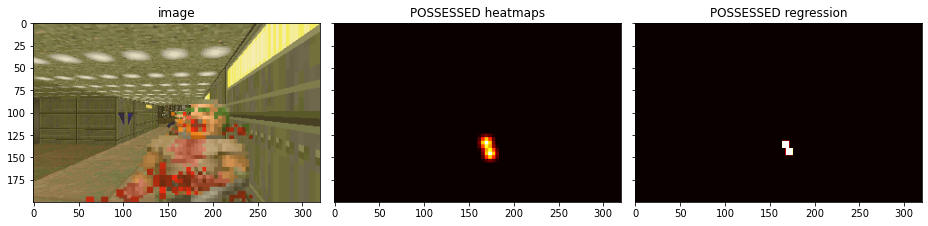

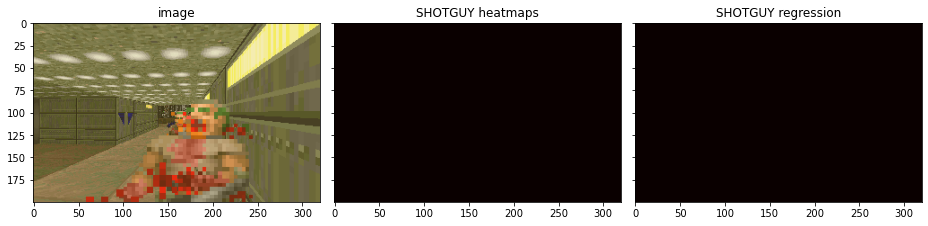

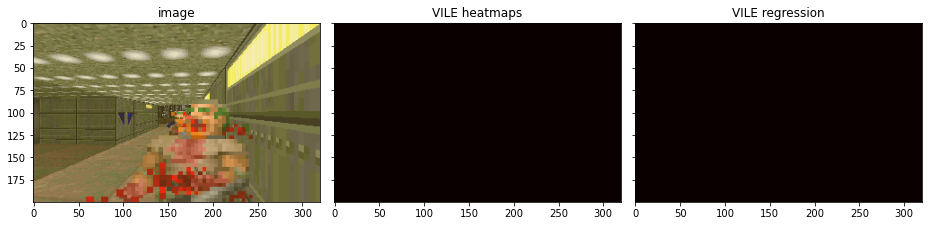

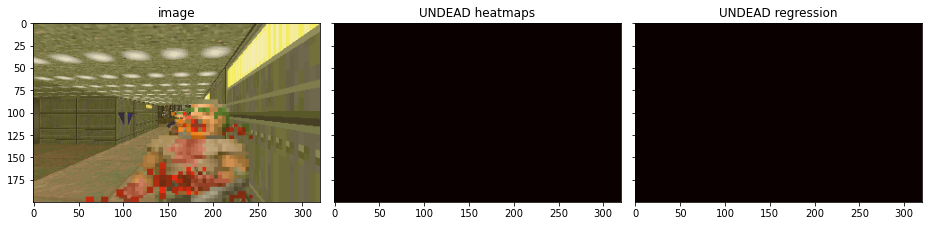

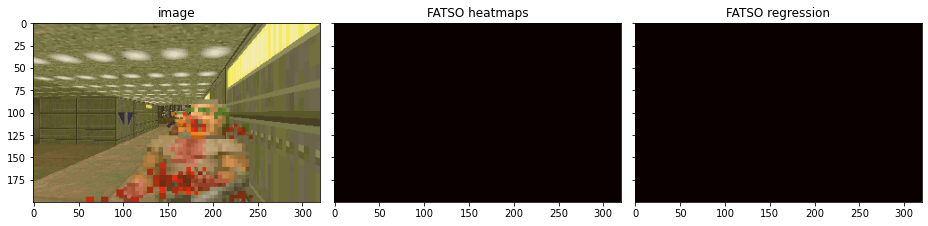

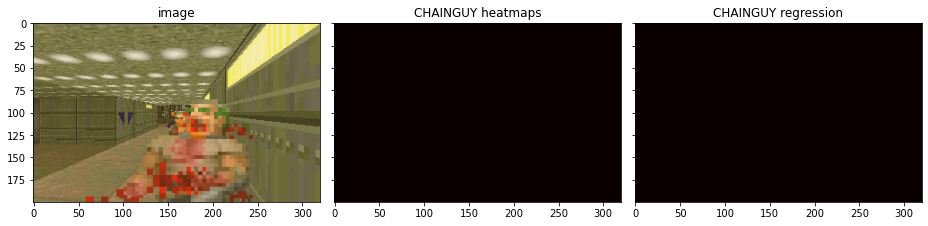

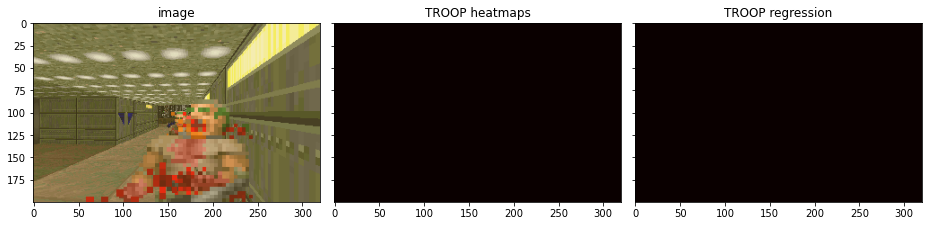

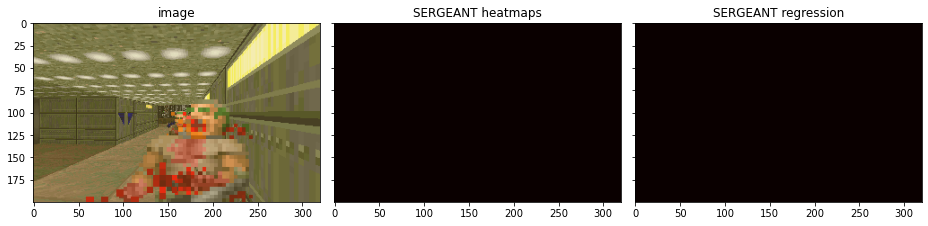

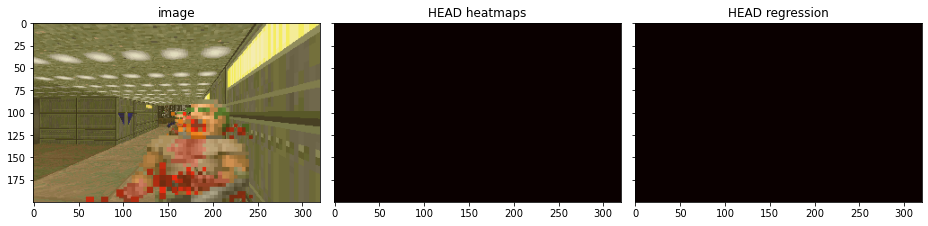

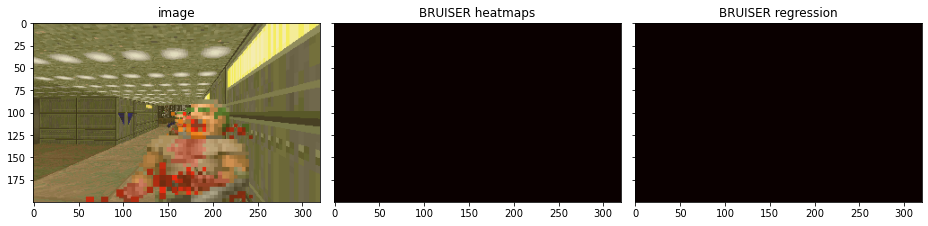

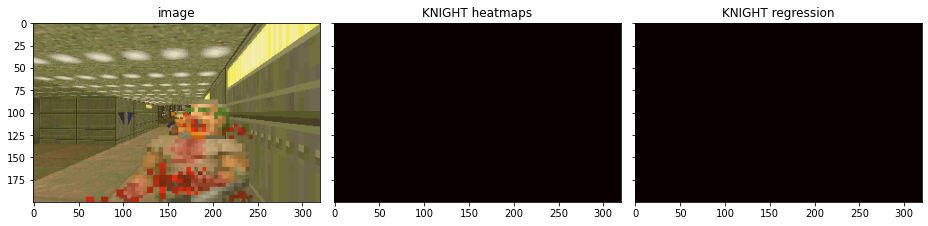

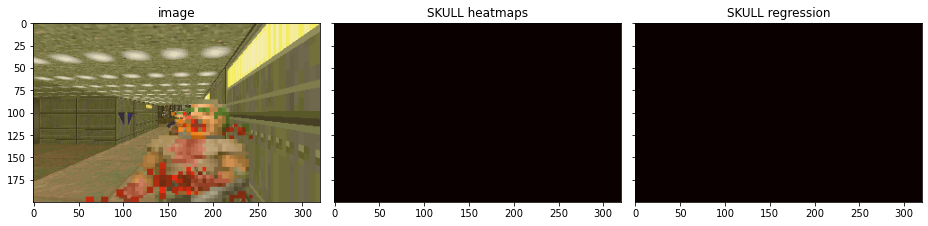

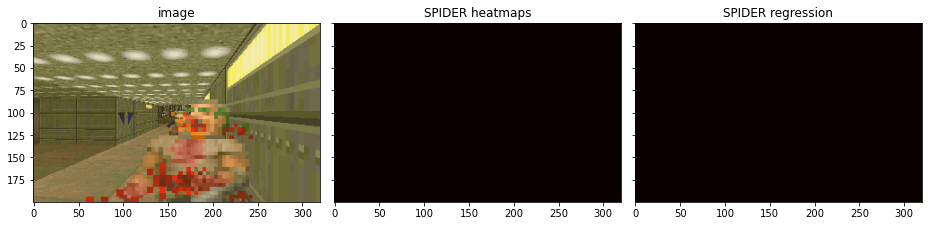

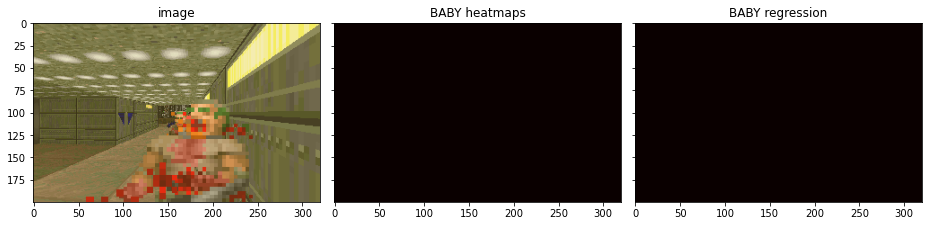

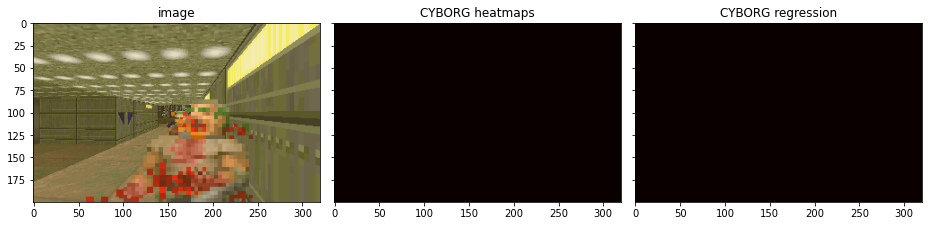

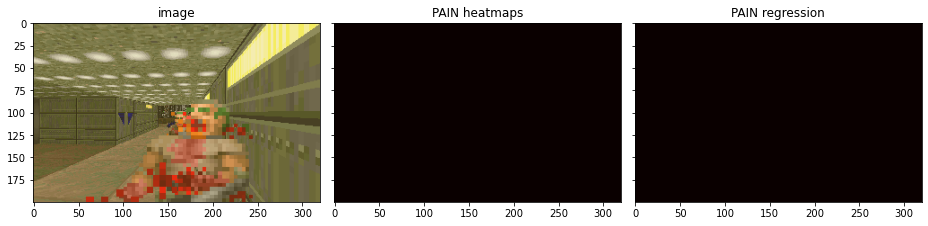

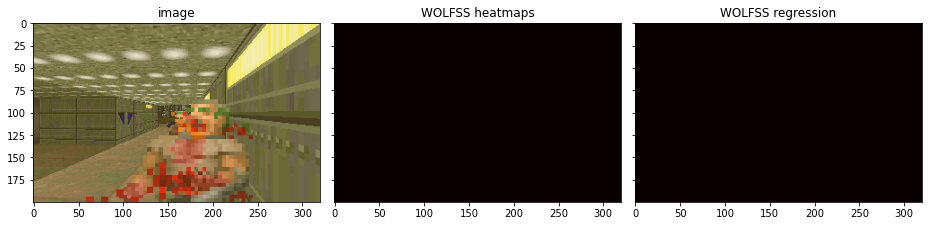

In [42]:
for type_id in range(training_pipe.dataset.descriptor.num_classes):
    image = cv2.cvtColor(sample["image_tensor"], cv2.COLOR_BGR2RGB)
    heatmap = sample["heatmap_tensor"][..., type_id]
    regression_locations = sample["regression_mask_tensor"]
    regression_locations = regression_locations[regression_locations[:, -1] == type_id]
    regression_locations = tf.stack([regression_locations[:, 1], regression_locations[:, 0]], axis=1)
    scatter_vals = tf.ones(len(regression_locations))
    scatter_shape = heatmap.shape[:2]
    regression_mask = tf.scatter_nd(regression_locations, scatter_vals, shape=scatter_shape).numpy()
    heatmap = cv2.resize(heatmap, (0, 0), fx=4, fy=4, interpolation=cv2.INTER_NEAREST)
    type_name = training_pipe.dataset.descriptor.enemy_types[type_id]
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, sharex="all", sharey="all", figsize=(13, 6))
    ax1.imshow(image)
    ax1.set_title("image")
    ax2.imshow(heatmap, vmin=0, vmax=1, cmap="hot")
    ax2.set_title(type_name + " heatmaps")
    regression_mask = cv2.resize(regression_mask, (0, 0), fx=4, fy=4, interpolation=cv2.INTER_NEAREST)
    ax3.imshow(regression_mask, vmin=0, vmax=1, cmap="hot")
    ax3.set_title(type_name + " regression")
    plt.tight_layout()
    plt.show()
